# 04 — When reuse hurts: negative transfer and catastrophic forgetting

Notebooks 01–03 showed reuse mostly *helping*. This notebook maps the
failure modes, in four short acts:

1. **A poisoned source** — transfer from a network trained on shuffled
   labels, and watch it land *below* scratch.
2. **The frozen-features ceiling** — freeze a mediocre source with plentiful
   target data and watch freezing turn "mediocre" into a hard cap.
3. **Fine-tuning learning rate** — an aggressive lr destroys the pretrained
   features and forfeits the transfer advantage.
4. **Catastrophic forgetting** — train the same encoder on a second task
   and watch the first task collapse; then fix it with 5% rehearsal.

**What the literature says.**
- *Negative transfer* — reuse that leaves you worse off than no transfer at
  all — is defined relative to the no-transfer baseline and appears whenever
  source and target are sufficiently mismatched (Wang, Dai, Póczos &
  Carbonell, *Characterizing and Avoiding Negative Transfer*, CVPR 2019).
- Sequentially trained connectionist networks overwrite old tasks —
  *catastrophic interference* (McCloskey & Cohen 1989). The root cause is
  that distributed representations share weights across tasks, so new-task
  gradients trample old-task solutions (French 1999, review).
- The oldest fix is also the most reliable: **rehearsal** — mix a little
  old-task data into new-task training (Robins 1995). Regularization
  alternatives such as EWC (Kirkpatrick et al. 2017) protect important
  weights instead of replaying data; we only demonstrate rehearsal here.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tllab").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

import tllab
from tllab import analysis, data, models, train

tllab.setup()

tllab: torch 2.13.0+cu130 | threads=4 | QUICK=False | root=/home/user/transfer-learning-lab


## Tasks, sources, and the probe pool

Two source models via the shared checkpoint mechanism (suite defaults:
20k examples, 6 epochs, seed 0): the honest `mnist` source, and the
poisoned `mnist:randlabel` source — same images, labels shuffled once and
fixed. The randlabel net can only *memorize* (Zhang et al. 2017), so its
test accuracy is chance and its features encode whatever memorization
needed, not class structure.

All linear probes in this notebook run against one pooled Fashion-MNIST
subset so embeddings are computed once per source and reused across seeds.

In [2]:
mnist_t = data.get_task("mnist")
fashion_t = data.get_task("fashion")

src_mnist = train.train_or_load_source("mnist")
src_rand = train.train_or_load_source("mnist:randlabel")

pool = data.subset(fashion_t, tllab.q(6000, 1200), seed=99)
print(pool)

[ckpt cached] mnist: test_acc=0.985
[ckpt cached] mnist:randlabel: test_acc=0.101
Task('fashion[n=6000,s=99]', 10 classes, train=6000, test=10000)


## Act 1 — a poisoned source

Target: Fashion-MNIST with only **n = 500** labels, 20 epochs at batch 32
(interpolating notebook 00's small-n schedule between its n=100 and n=1000
settings). Four conditions, 3 seeds:

| condition | encoder init | encoder trained? | LR |
|---|---|---|---|
| scratch | random | yes | 1e-3 |
| fine-tune (mnist src) | honest source | yes | encoder 1e-4, head 1e-3 |
| fine-tune (randlabel src) | poisoned source | yes | encoder 1e-4, head 1e-3 |
| frozen probe (randlabel src) | poisoned source | no | 1e-2 (head only) |

The frozen probe inherits the poisoned representation *in full* — that is
where negative transfer should be unambiguous. Fine-tuning from the same
poison can partially escape, because a bad init is still just an init once
every weight is allowed to move — expect it near (not necessarily below)
scratch, so that comparison gets a soft claim. The honest-source fine-tune
is a control, not a hero: notebooks 01 and 03 showed mnist→fashion is a
*distant* pairing, so expect it to track scratch, not to beat it — the
contrast that matters here is honest-source ≈ scratch vs poisoned-frozen
≪ scratch.

In [3]:
N1 = tllab.q(500, 100)
E1 = tllab.q(20, 2)


def poisoned_source() -> pd.DataFrame:
    rows = []
    for seed in tllab.seeds():
        sub = data.subset(fashion_t, N1, seed)

        m = models.new_cnn(fashion_t.n_classes, seed)
        scratch = train.fit(m, sub, epochs=E1, batch_size=32,
                            seed=seed).final_acc

        m = models.transfer_first_k(src_mnist, 5, fashion_t.n_classes, seed)
        ft_good = train.fit(m, sub, epochs=E1, lr=1e-4, head_lr=1e-3,
                            batch_size=32, seed=seed).final_acc

        m = models.transfer_first_k(src_rand, 5, fashion_t.n_classes, seed)
        ft_bad = train.fit(m, sub, epochs=E1, lr=1e-4, head_lr=1e-3,
                           batch_size=32, seed=seed).final_acc

        probe_bad = train.linear_probe(src_rand, pool, n_train=N1, seed=seed,
                                       cache_key="04-randlabel")

        for cond, acc in [("scratch", scratch), ("fine-tune mnist", ft_good),
                          ("fine-tune randlabel", ft_bad),
                          ("probe randlabel", probe_bad)]:
            rows.append({"condition": cond, "seed": seed, "acc": acc})
        print(f"  seed={seed}: scratch={scratch:.3f} ft-mnist={ft_good:.3f} "
              f"ft-rand={ft_bad:.3f} probe-rand={probe_bad:.3f}")
    return pd.DataFrame(rows)


df1 = train.cached_sweep("04_poisoned_source", poisoned_source)
df1.groupby("condition")["acc"].agg(["mean", "min", "max"]).round(3)

[sweep cached] 04_poisoned_source.csv


,mean,min,max
condition,,,
fine-tune mnist,0.735,0.730,0.739
fine-tune randlabel,0.655,0.637,0.668
probe randlabel,0.276,0.243,0.322
scratch,0.756,0.749,0.759


## Act 2 — the frozen-features ceiling

Act 1's frozen probe used a *bad* source at *tiny* n. This act shows the
subtler trap: an honest-but-mismatched source (`mnist`, handwritten
strokes) frozen under a *plentiful* target (Fashion-MNIST, **n = 5000**).
Frozen mismatched features don't corrupt anything — they merely **underuse
the data**: however many labels arrive, the head can only re-weight 128
digit-tuned features, while the scratch network keeps converting labels
into better features. This is negative transfer in Wang et al.'s (2019)
relative sense — worse than the no-transfer baseline — even though the
source is perfectly honest.

In [4]:
N2 = tllab.q(5000, 500)


def frozen_ceiling() -> pd.DataFrame:
    m = models.new_cnn(fashion_t.n_classes, 0)
    res = train.fit(m, data.subset(fashion_t, N2, 0),
                    epochs=tllab.q(15, 2), seed=0, eval_every=5)
    print(f"  scratch n={N2}: {res.final_acc:.3f} ({res.wall_s:.0f}s)")
    probe = train.linear_probe(src_mnist, pool, n_train=N2, seed=0,
                               cache_key="04-mnist")
    print(f"  frozen mnist probe n={N2}: {probe:.3f}")
    return pd.DataFrame([
        {"condition": "scratch", "n_train": N2, "acc": res.final_acc},
        {"condition": "frozen probe", "n_train": N2, "acc": probe}])


df2 = train.cached_sweep("04_frozen_ceiling", frozen_ceiling)
df2

[sweep cached] 04_frozen_ceiling.csv


,condition,n_train,acc
0,scratch,5000,0.8408
1,frozen probe,5000,0.7696


figure -> artifacts/figures/04_negative_bars.png


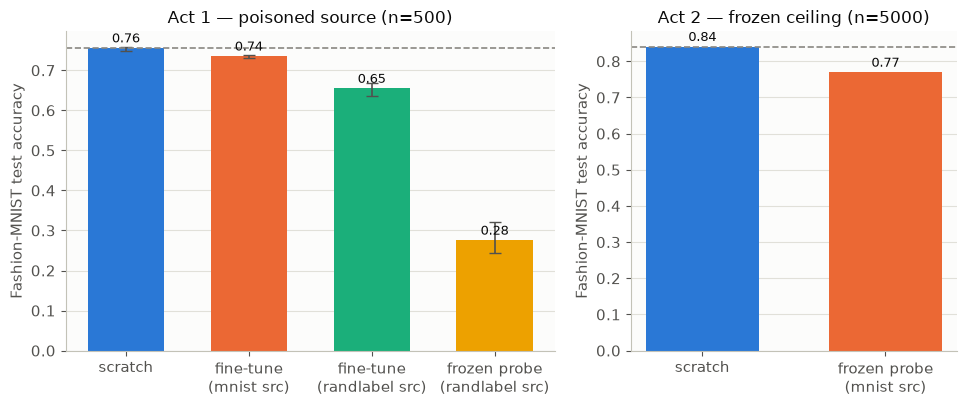

In [5]:
g1 = df1.groupby("condition")["acc"]
ORDER1 = ["scratch", "fine-tune mnist", "fine-tune randlabel",
          "probe randlabel"]
LABELS1 = ["scratch", "fine-tune\n(mnist src)", "fine-tune\n(randlabel src)",
           "frozen probe\n(randlabel src)"]
g2 = df2.set_index("condition")["acc"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.8, 4.2),
                               gridspec_kw={"width_ratios": [3, 2]})
analysis.plot_bars(LABELS1, [g1.mean()[c] for c in ORDER1],
                   [(g1.min()[c], g1.max()[c]) for c in ORDER1], ax=ax1,
                   ylabel="Fashion-MNIST test accuracy",
                   title=f"Act 1 — poisoned source (n={N1})",
                   baseline=g1.mean()["scratch"], baseline_label="scratch mean")
analysis.plot_bars(["scratch", "frozen probe\n(mnist src)"],
                   [g2["scratch"], g2["frozen probe"]], ax=ax2,
                   ylabel="Fashion-MNIST test accuracy",
                   title=f"Act 2 — frozen ceiling (n={N2})",
                   baseline=g2["scratch"], baseline_label="scratch")
analysis.savefig("04_negative_bars")

## Act 3 — fine-tuning learning rate: how to destroy what you paid for

This act needs a pairing where transfer is *genuinely valuable*, so there
is something to destroy: the related pair from notebook 01 (`mnist:5-9` →
`mnist:0-4`) at the few-shot end, **n = 25** (five examples per class),
where gentle fine-tuning beats scratch by ~9 points. Encoder lr ∈
{1e-4, 1e-3, 1e-2} with the fresh head always at 1e-3, plus a scratch
reference, 60 epochs, 3 seeds. At encoder lr 1e-2 the first large gradient
steps overwrite the pretrained weights before the head has learned anything
— the init is effectively randomized, and with 25 examples there is no
second chance: the run degenerates to (noisy) scratch. Footnote from a
pilot on a *distant* pair (mnist→fashion at n=1000): there, aggressive
encoder lr actually *helped*, precisely because the pretrained features
carried no value worth preserving — erasing them cost nothing. The lr knob
only "destroys what you paid for" when you actually got something for it.

[ckpt cached] mnist:5-9: test_acc=0.988
[sweep cached] 04_lr_sweep.csv


figure -> artifacts/figures/04_lr_sweep.png


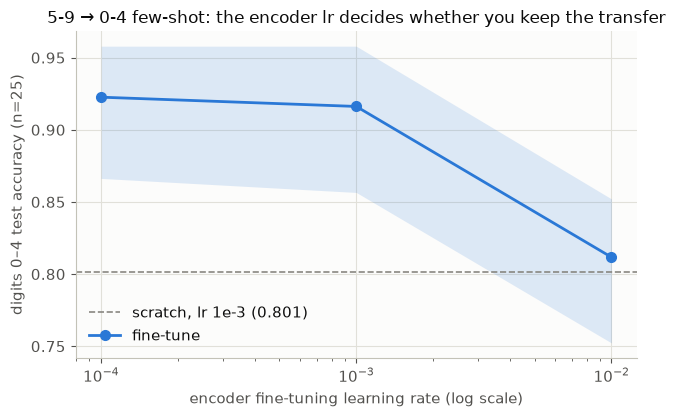

In [6]:
src_rel = train.train_or_load_source("mnist:5-9")
target04 = data.get_task("mnist:0-4")
N3 = tllab.q(25, 20)
E3 = tllab.q(60, 3)
FT_LRS = [1e-4, 1e-3, 1e-2]


def lr_sweep() -> pd.DataFrame:
    rows = []
    for seed in tllab.seeds():
        sub = data.subset(target04, N3, seed)

        m = models.new_cnn(target04.n_classes, seed)
        sc = train.fit(m, sub, epochs=E3, batch_size=16, seed=seed,
                       eval_every=10).final_acc
        rows.append({"condition": "scratch", "lr": 1e-3, "seed": seed,
                     "acc": sc})
        print(f"  scratch        seed={seed}: {sc:.3f}")

        for lr in FT_LRS:
            m = models.transfer_first_k(src_rel, 5, target04.n_classes, seed)
            acc = train.fit(m, sub, epochs=E3, lr=lr, head_lr=1e-3,
                            batch_size=16, seed=seed,
                            eval_every=10).final_acc
            rows.append({"condition": "fine-tune", "lr": lr, "seed": seed,
                         "acc": acc})
            print(f"  ft lr={lr:<7g} seed={seed}: {acc:.3f}")
    return pd.DataFrame(rows)


df3 = train.cached_sweep("04_lr_sweep", lr_sweep)
scratch3 = df3[df3.condition == "scratch"]["acc"].mean()

plt.figure(figsize=(6.6, 4.3))
ax = plt.gca()
ax.axhline(scratch3, color="#898781", linestyle="--", linewidth=1.2,
           label=f"scratch, lr 1e-3 ({scratch3:.3f})")
analysis.plot_curves(df3[df3.condition == "fine-tune"], x="lr", y="acc",
                     hue="condition", ax=ax, logx=True,
                     ylabel="digits 0–4 test accuracy (n=25)",
                     title="5-9 → 0-4 few-shot: the encoder lr decides whether "
                           "you keep the transfer")
ax.set_xlabel("encoder fine-tuning learning rate (log scale)")
analysis.savefig("04_lr_sweep")

## Act 4 — catastrophic forgetting, and the 5% rehearsal fix

**Design.** Train task A (`mnist`, 5000 examples, 5 epochs), snapshot its
encoder, then train task B (`fashion`) two ways:

- **Naive arm — pure representation forgetting.** The task-B net *shares
  the same encoder object* as the task-A net; only B's fresh head and the
  shared encoder receive gradients, while A's original head is never
  touched. Re-evaluating the A-net after every B epoch therefore measures
  exactly how far the *representation* has drifted out from under a
  perfectly preserved head — forgetting with no head-related excuses
  (McCloskey & Cohen 1989; French 1999).
- **Rehearsal arm.** A multi-task trunk warm-started from the pre-drift
  encoder snapshot trains on all 5000 fashion examples while replaying just
  **250 MNIST examples (5%)** through a fresh A head — Robins' (1995)
  rehearsal, the oldest and still most effective fix. (EWC — Kirkpatrick
  et al. 2017 — would instead penalize movement of A-critical weights; not
  run here.) Because the A head is fresh, its accuracy comes from the mixed
  training itself; epoch 0 is anchored at the pre-drift accuracy for both
  arms, where the encoders are still identical.

Single seed — the effect is dozens of points, not a coin flip.

In [7]:
N4 = tllab.q(5000, 500)
E4 = tllab.q(5, 1)
N_REHEARSE = tllab.q(250, 50)


def forgetting_runs() -> pd.DataFrame:
    mA = models.new_cnn(10, 0)
    train.fit(mA, data.subset(mnist_t, N4, 0), epochs=E4, seed=0)
    acc_before = train.evaluate(mA, mnist_t)
    encA = models.clone_encoder(mA)  # snapshot BEFORE it drifts
    print(f"  task A (mnist) trained: acc={acc_before:.3f}")

    # Naive arm: B's net shares the SAME encoder object; A's head untouched.
    tllab.set_seed(1)
    mB = models.SmallCNN(10)
    mB.encoder = mA.encoder
    naive = train.fit(
        mB, data.subset(fashion_t, N4, 0), epochs=E4, seed=0, lr=1e-3,
        track={"mnist_acc": lambda m: train.evaluate(mA, mnist_t)})
    print(f"  naive:     fashion={naive.final_acc:.3f}  "
          f"mnist now={naive.history['mnist_acc'].iloc[-1]:.3f}")

    # Rehearsal arm: warm-started trunk, 5% task-A replay, fresh A head.
    res_r, _ = train.fit_multitask(
        {"fashion": data.subset(fashion_t, N4, 0),
         "mnist": data.subset(mnist_t, N_REHEARSE, 0)},
        main="fashion", epochs=E4, seed=0, init_encoder=encA,
        track={"mnist_acc": lambda net: train.evaluate_head(net, mnist_t,
                                                            "mnist")})
    print(f"  rehearsal: fashion={res_r.final_acc:.3f}  "
          f"mnist now={res_r.history['mnist_acc'].iloc[-1]:.3f}")

    rows = [{"arm": arm, "epoch": 0, "mnist_acc": acc_before,
             "fashion_acc": None} for arm in ("naive", "rehearsal")]
    for arm, hist in [("naive", naive.history), ("rehearsal", res_r.history)]:
        for _, r in hist.iterrows():
            rows.append({"arm": arm, "epoch": int(r["epoch"]),
                         "mnist_acc": float(r["mnist_acc"]),
                         "fashion_acc": float(r["test_acc"])})
    return pd.DataFrame(rows)


df4 = train.cached_sweep("04_forgetting", forgetting_runs)
df4.pivot_table(index="epoch", columns="arm", values="mnist_acc").round(3)

[sweep cached] 04_forgetting.csv


arm,naive,rehearsal
epoch,,
0,0.945,0.945
1,0.639,0.895
2,0.640,0.917
3,0.605,0.929
4,0.582,0.930
5,0.545,0.921


figure -> artifacts/figures/04_forgetting_curve.png


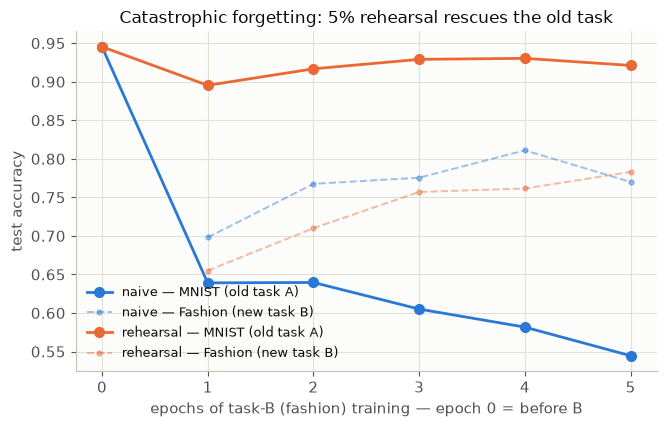

In [8]:
plt.figure(figsize=(6.8, 4.4))
ax = plt.gca()
for i, arm in enumerate(["naive", "rehearsal"]):
    adf = df4[df4.arm == arm].sort_values("epoch")
    color = tllab.PALETTE[i]
    ax.plot(adf["epoch"], adf["mnist_acc"], marker="o", color=color,
            label=f"{arm} — MNIST (old task A)")
    fdf = adf.dropna(subset=["fashion_acc"])
    ax.plot(fdf["epoch"], fdf["fashion_acc"], linestyle="--", marker=".",
            linewidth=1.4, color=color, alpha=0.45,
            label=f"{arm} — Fashion (new task B)")
ax.set_xlabel("epochs of task-B (fashion) training — epoch 0 = before B")
ax.set_ylabel("test accuracy")
ax.set_title("Catastrophic forgetting: 5% rehearsal rescues the old task")
ax.legend(fontsize=9)
analysis.savefig("04_forgetting_curve")

## Takeaways

- **Frozen features from a poisoned source are worse than nothing.** The
  randlabel probe sits ~50 points below scratch — genuine negative transfer
  in Wang et al.'s (2019) sense. Fine-tuning from the same poison recovers
  most of the way back: once every weight can move, a bad init is mostly
  just an init (though it still trails scratch here). Meanwhile the
  *honest* mnist source neither helps nor hurts fashion much — a distant
  source is closer to a no-op than to a boost (notebooks 01 and 03). At
  this scale the reliable damage comes from keeping bad features frozen.
- **Freezing turns "mediocre" into a ceiling.** With 5000 fashion labels,
  frozen mnist features cap the probe several points below a converged
  scratch run. The source didn't corrupt anything — freezing just forbade
  the network from using the data it had. Rule of thumb: the more target
  data, the less you should freeze (notebook 01's crossover, completed).
- **The encoder lr is the knob between "adapt" and "erase" — when the
  features are worth keeping.** On the related few-shot pair, encoder lr
  1e-4 keeps the ~9-point transfer advantage; 1e-2 erases the pretrained
  weights in the first steps and collapses to scratch level. On a distant
  pair the same aggressive lr is harmless — there was nothing to erase.
- **Forgetting is fast, rehearsal is cheap.** Five fashion epochs drag
  MNIST accuracy down by tens of points under a frozen head — the shared
  representation simply left (McCloskey & Cohen 1989; French 1999).
  Replaying 5% of task-A data restores most of it while matching the naive
  arm on task B (Robins 1995). Regularization methods like EWC
  (Kirkpatrick et al. 2017) exist for when old data can't be kept.

**References.** Wang, Dai, Póczos & Carbonell, *Characterizing and
Avoiding Negative Transfer* (CVPR 2019). McCloskey & Cohen, *Catastrophic
interference in connectionist networks* (Psych. of Learning & Motivation,
1989). French, *Catastrophic forgetting in connectionist networks* (Trends
Cogn. Sci., 1999). Robins, *Catastrophic forgetting, rehearsal and
pseudorehearsal* (Connection Science, 1995). Kirkpatrick et al.,
*Overcoming catastrophic forgetting in neural networks* (PNAS 2017).
Zhang et al. (ICLR 2017) for randlabel memorization.

In [9]:
if not tllab.config.QUICK:
    # Act 1 — poisoned source
    m1 = df1.groupby("condition")["acc"].mean()
    analysis.claim("frozen randlabel probe < scratch − 5 pts (negative transfer)",
                   m1["probe randlabel"] < m1["scratch"] - 0.05,
                   f"{m1['probe randlabel']:.3f} vs scratch {m1['scratch']:.3f}",
                   hard=True)
    analysis.claim("honest mnist fine-tune within 3 pts of scratch "
                   "(distant source ≈ no help, no harm)",
                   abs(m1["fine-tune mnist"] - m1["scratch"]) < 0.03,
                   f"{m1['fine-tune mnist']:.3f} vs {m1['scratch']:.3f}")
    analysis.claim("randlabel fine-tune no better than scratch (+1 pt tol.)",
                   m1["fine-tune randlabel"] <= m1["scratch"] + 0.01,
                   f"{m1['fine-tune randlabel']:.3f} vs {m1['scratch']:.3f}")

    # Act 2 — frozen ceiling
    m2 = df2.set_index("condition")["acc"]
    analysis.claim("frozen mnist probe < scratch − 5 pts at n=5000 (ceiling)",
                   m2["frozen probe"] < m2["scratch"] - 0.05,
                   f"{m2['frozen probe']:.3f} vs {m2['scratch']:.3f}", hard=True)

    # Act 3 — fine-tuning lr (related pair, so there is value to destroy)
    m3 = df3[df3.condition == "fine-tune"].groupby("lr")["acc"].mean()
    analysis.claim("gentle fine-tune beats scratch on the related pair",
                   m3[1e-4] > scratch3,
                   f"{m3[1e-4]:.3f} vs scratch {scratch3:.3f}", hard=True)
    analysis.claim("gentle beats aggressive (encoder lr 1e-4 > 1e-2)",
                   m3[1e-4] > m3[1e-2],
                   f"{m3[1e-4]:.3f} vs {m3[1e-2]:.3f}", hard=True)
    analysis.claim("aggressive fine-tune (1e-2) ≤ scratch + 3 pts (erased)",
                   m3[1e-2] <= scratch3 + 0.03,
                   f"{m3[1e-2]:.3f} vs scratch {scratch3:.3f}")

    # Act 4 — forgetting and rehearsal
    p4 = df4.pivot_table(index="epoch", columns="arm", values="mnist_acc")
    before = p4["naive"].loc[0]
    naive_final = p4["naive"].loc[p4.index.max()]
    reh_final = p4["rehearsal"].loc[p4.index.max()]
    analysis.claim("naive forgetting drop > 20 pts",
                   before - naive_final > 0.20,
                   f"{before:.3f} → {naive_final:.3f}", hard=True)
    analysis.claim("5% rehearsal retains ≥ naive + 10 pts",
                   reh_final >= naive_final + 0.10,
                   f"{reh_final:.3f} vs naive {naive_final:.3f}")

CLAIM CHECK [PASS] frozen randlabel probe < scratch − 5 pts (negative transfer) — 0.276 vs scratch 0.756
CLAIM CHECK [PASS] honest mnist fine-tune within 3 pts of scratch (distant source ≈ no help, no harm) — 0.735 vs 0.756
CLAIM CHECK [PASS] randlabel fine-tune no better than scratch (+1 pt tol.) — 0.655 vs 0.756
CLAIM CHECK [PASS] frozen mnist probe < scratch − 5 pts at n=5000 (ceiling) — 0.770 vs 0.841
CLAIM CHECK [PASS] gentle fine-tune beats scratch on the related pair — 0.923 vs scratch 0.801
CLAIM CHECK [PASS] gentle beats aggressive (encoder lr 1e-4 > 1e-2) — 0.923 vs 0.812
CLAIM CHECK [PASS] aggressive fine-tune (1e-2) ≤ scratch + 3 pts (erased) — 0.812 vs scratch 0.801
CLAIM CHECK [PASS] naive forgetting drop > 20 pts — 0.945 → 0.545
CLAIM CHECK [PASS] 5% rehearsal retains ≥ naive + 10 pts — 0.921 vs naive 0.545
